# Variability classification for a single brown dwarf spectrum

Classify a brown dwarf spectrum as a candidate variable or non-variable using the NIR spectral-index variability scheme implemented in `seda.classify_variability`.

This tutorial shows how to:
- read an input spectrum,
- run the variability classification for either an L or T dwarf scheme,
- inspect the output stored in the `VariabilityResult` object,
- and optionally generate diagnostic plots of the index bandpasses and the index–index variability diagrams.

In [1]:
import seda
from seda.variability import classify_variability
import numpy as np
import os
from astropy.io import ascii
from numpy.typing import ArrayLike
from typing import Tuple, Literal, Optional, Union, Dict, List, Mapping
from matplotlib import Path


    SEDA v0.8.10.dev48 package imported


### Read the spectrum of interest

As an example, let us read a near-infrared brown dwarf spectrum.
You can replace this file by your own spectrum, as long as it contains wavelength and flux columns.

In [2]:
# path to the seda package
path_seda = Path(seda.__file__).resolve().parents[1]
spec_name = (path_seda / "docs" / "notebooks" / 
             "data" / "0439-nirspec-Ldwarf.txt") 
spec = np.loadtxt(spec_name, comments='#').T

wave = spec[0]   # wavelength in microns
flux = spec[1]   # flux

If your input file contains uncertainties, you can still use them for your own bookkeeping, but the variability module currently requires only wavelength and flux arrays.

### Explore the function documentation
As for other SEDA functions, you can inspect the function description directly in the notebook:

In [3]:
help(seda.variability.classify_variability)

Help on function classify_variability in module seda.variability:

classify_variability(wavelength, flux, *, spectral_type: str, normalize: bool = True, scheme: Optional[str] = None, plot_diagrams: bool = False, plot_index_windows: bool = False, plot_save: Union[bool, str] = False, show: bool = True) -> seda.variability.VariabilityResult
    Description:
    ------------
    Classify a brown dwarf as candidate variable or non-variable using
    NIR spectral index–index variability regions.
    
    This is the main public interface for variability classification in SEDA.
    It computes the required spectral indices, evaluates the polygon-based
    variability criteria, and optionally produces diagnostic plots.
    
    Parameters:
    -----------
    - wavelength : array-like
        Wavelength array (microns).
    - flux : array-like
        Flux array corresponding to `wavelength`.
    - spectral_type : {"L", "T"}
        Spectral type scheme to use for the classification.
    - nor

### Run the variability classification

Choose the spectral-type scheme to use:

- `"T"` for the T-dwarf variability scheme,

- `"L"` for the L-dwarf variability scheme.

The parameter `normalize` controls whether the spectrum is median-normalized before computing the indices.

In [4]:
result = classify_variability(
    wave,
    flux,
    spectral_type="L",
    normalize=False,
)

### Inspect the classification output
The function returns a `VariabilityResult` object containing the computed indices and the classification summary.

In [5]:
print(result.is_candidate_variable)
print(result.n_regions_triggered, "/", result.n_regions_total)
print(result.indices)
print(result.regions_triggered)
print(result.summary())

True
8 / 15
{'mostH': np.float64(1.5087388779766489), 'mostJ': np.float64(0.24971511702040977), 'less': np.float64(1.781314374877187), 'Jcurve': np.float64(1.192644800500469), 'H2OJ': np.float64(0.718355884207247), 'CH4J': np.float64(0.7325891829647628)}
['01', '02', '03', '10', '11', '21', '23', '32']
Scheme: Oliveros-Gomez+2024
Spectral type: L
Triggered regions: 8/15 (threshold ≥ 8)
Classification: candidate VARIABLE


The most relevant attributes are:
- `result.is_candidate_variable`
Final classification flag.
- `result.n_regions_triggered`
Number of variability regions in which the target falls.
- `result.n_regions_total`
Total number of regions considered for the selected spectral-type scheme.
- `result.indices`
Dictionary containing the computed NIR spectral indices.
- `result.regions_triggered`
List of region identifiers triggered by the target.
- `result.summary()`
Human-readable summary of the classification.

### Plot the index bandpasses used in the classification

To visualize the spectral regions used to compute the variability indices, set `plot_index_windows=True`.

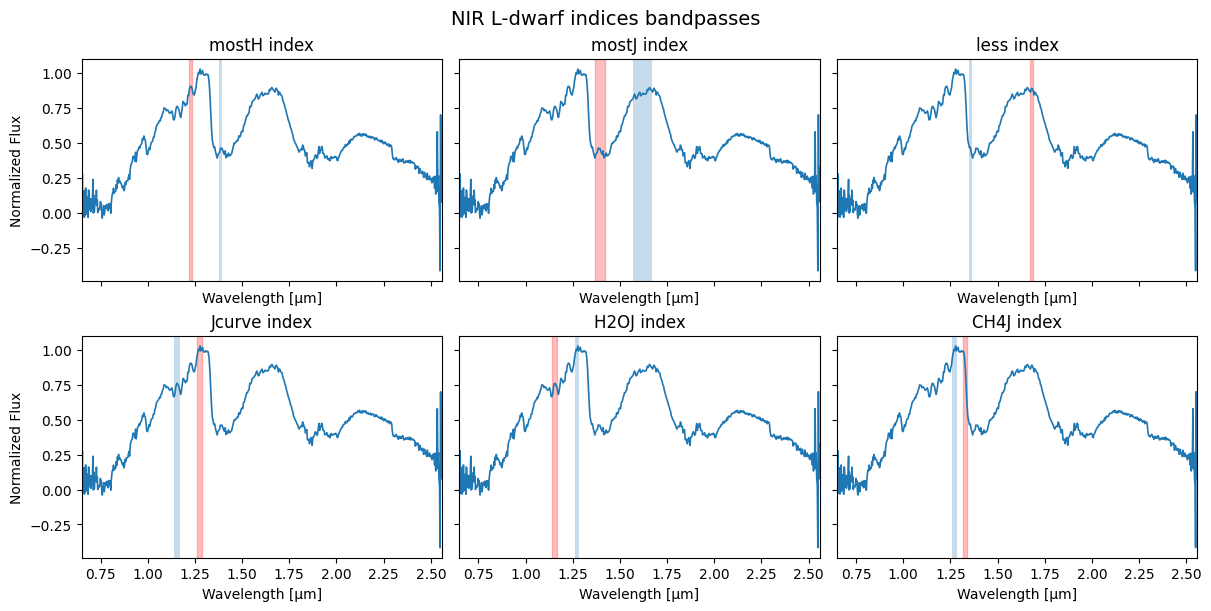

In [6]:
result = classify_variability(
    wave,
    flux,
    spectral_type="L",
    normalize=False,
    plot_index_windows=True,
)

This produces a multi-panel figure showing the input spectrum and the numerator/denominator wavelength windows used for each index in the selected L- or T-dwarf scheme.

If desired, the figure can be saved automatically:

### Plot the index–index variability diagrams
To reproduce the variability classification diagrams, set `plot_diagrams=True`.

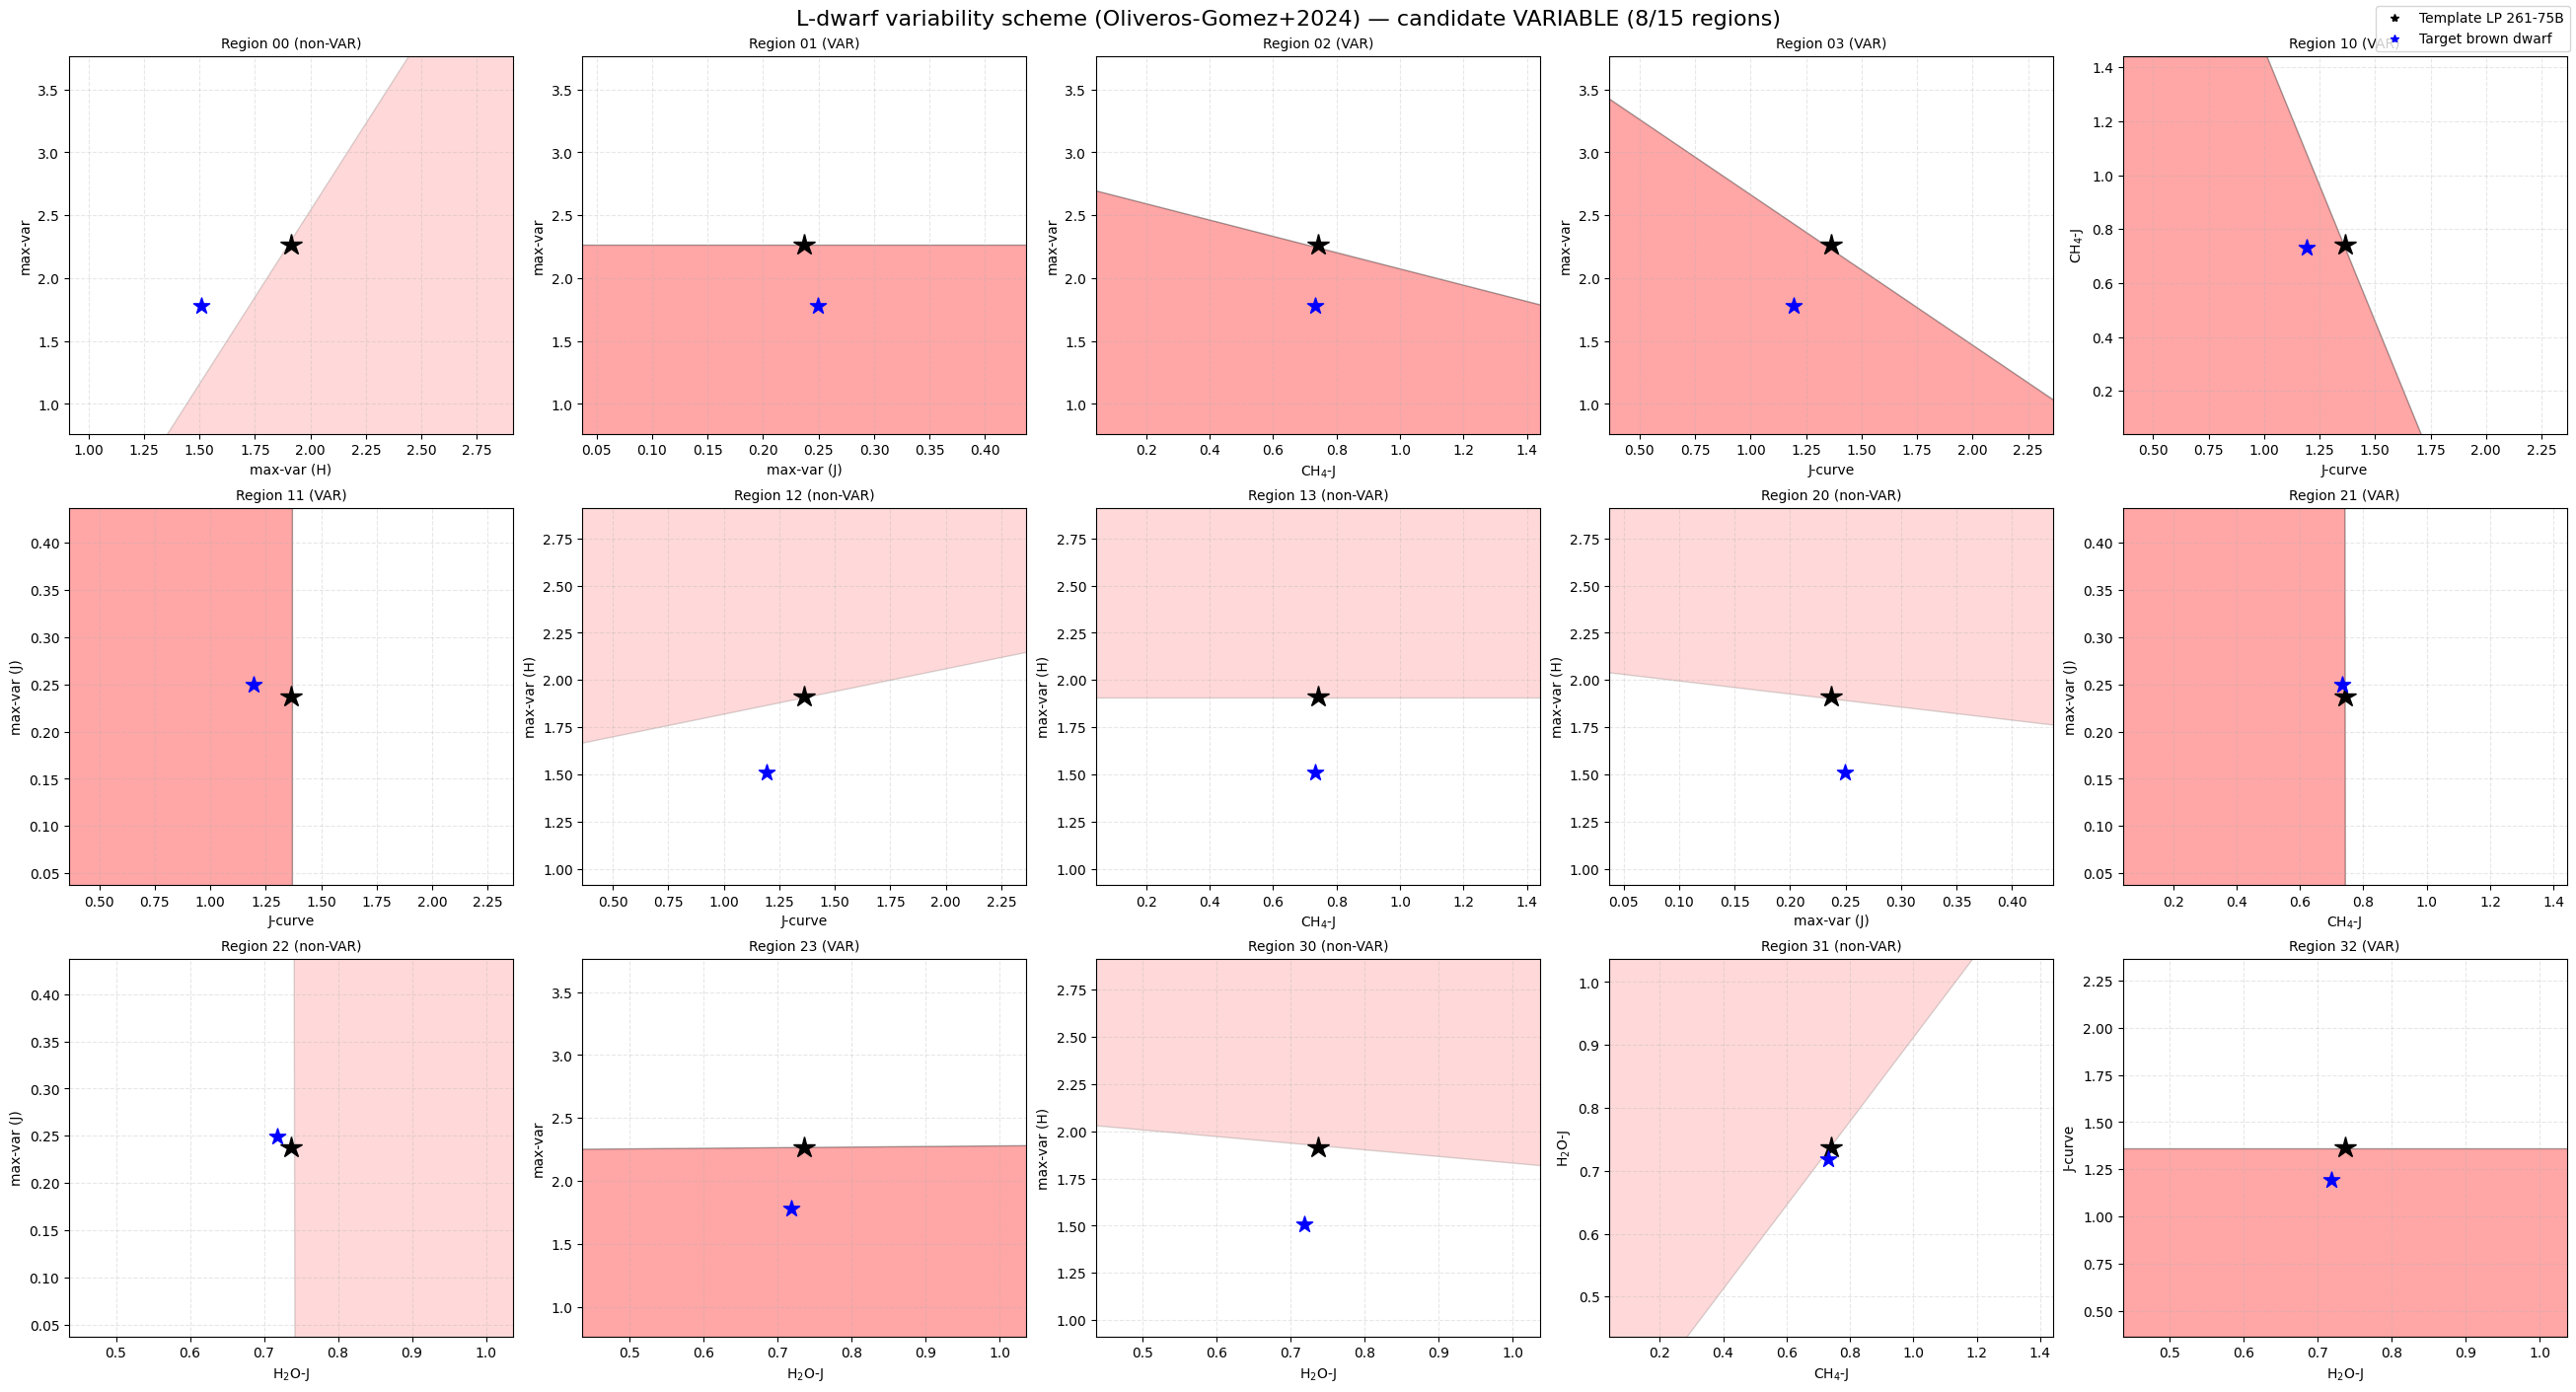

In [7]:
result = classify_variability(
    wave,
    flux,
    spectral_type="L",
    normalize=False,
    plot_diagrams=True,
)

These diagrams show:
- the polygonal variability regions,
- the template/reference object,
- and the position of the target object in index–index space.

You can also save the figure:

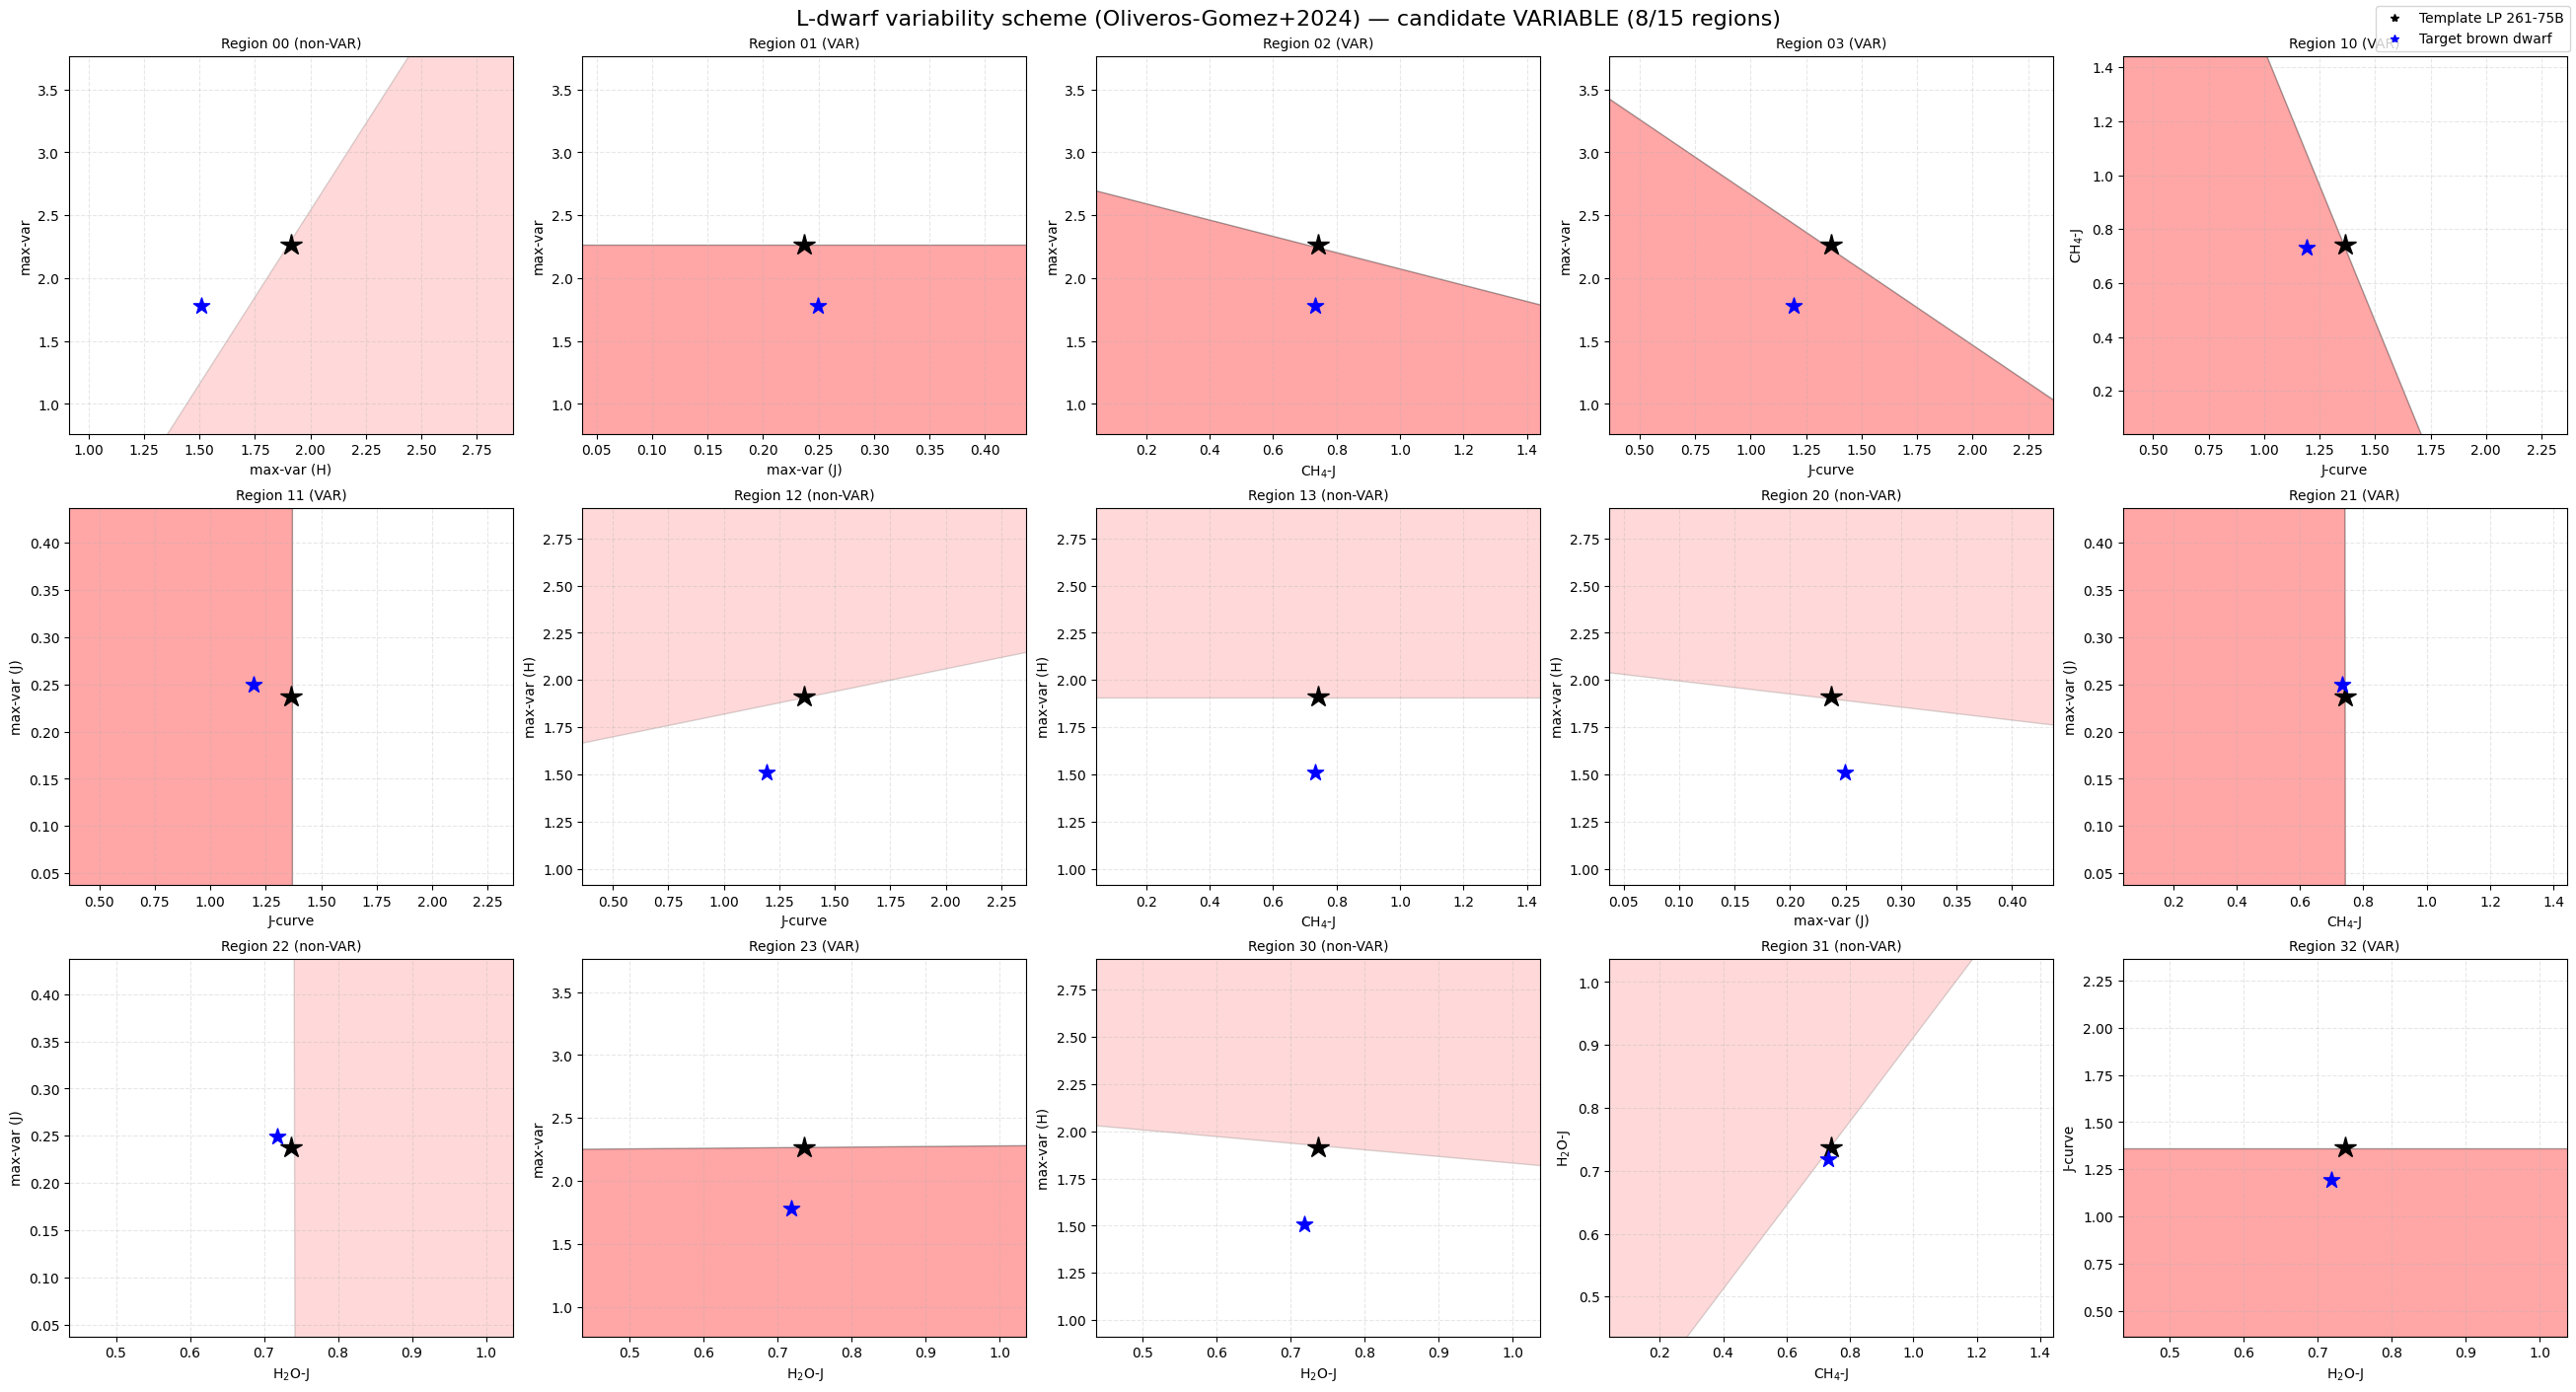

In [8]:
result = classify_variability(
    wave,
    flux,
    spectral_type="L",
    normalize=False,
    plot_diagrams=True,
    plot_save=True,
)

### Generate both diagnostic plots at once

Both the index-window plot and the index–index diagrams can be generated in a single call:

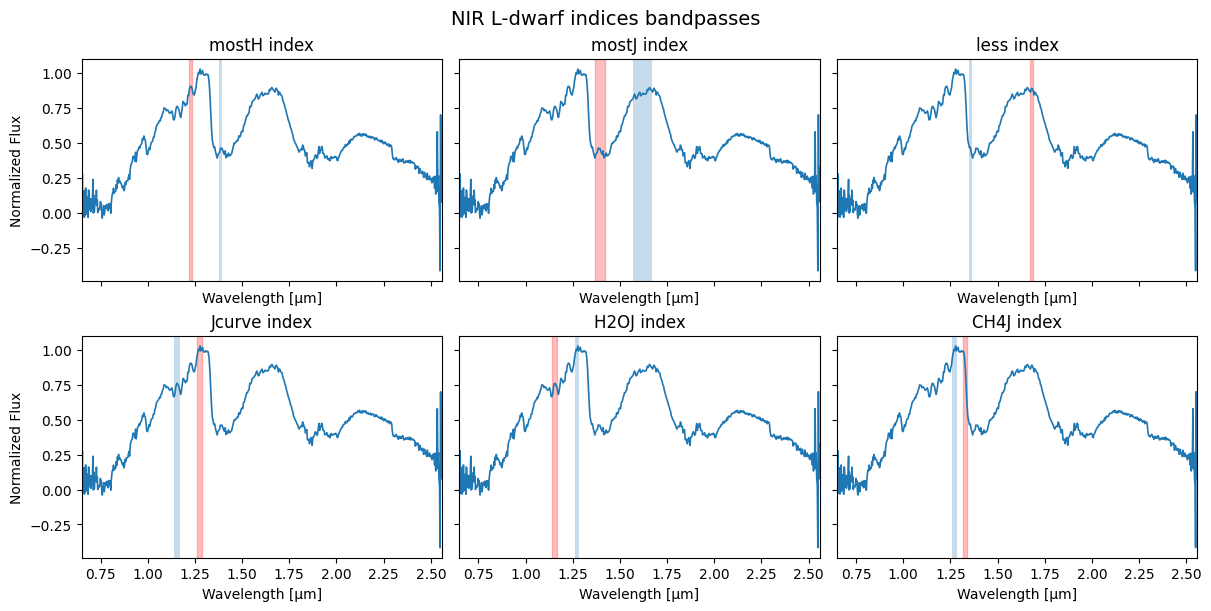

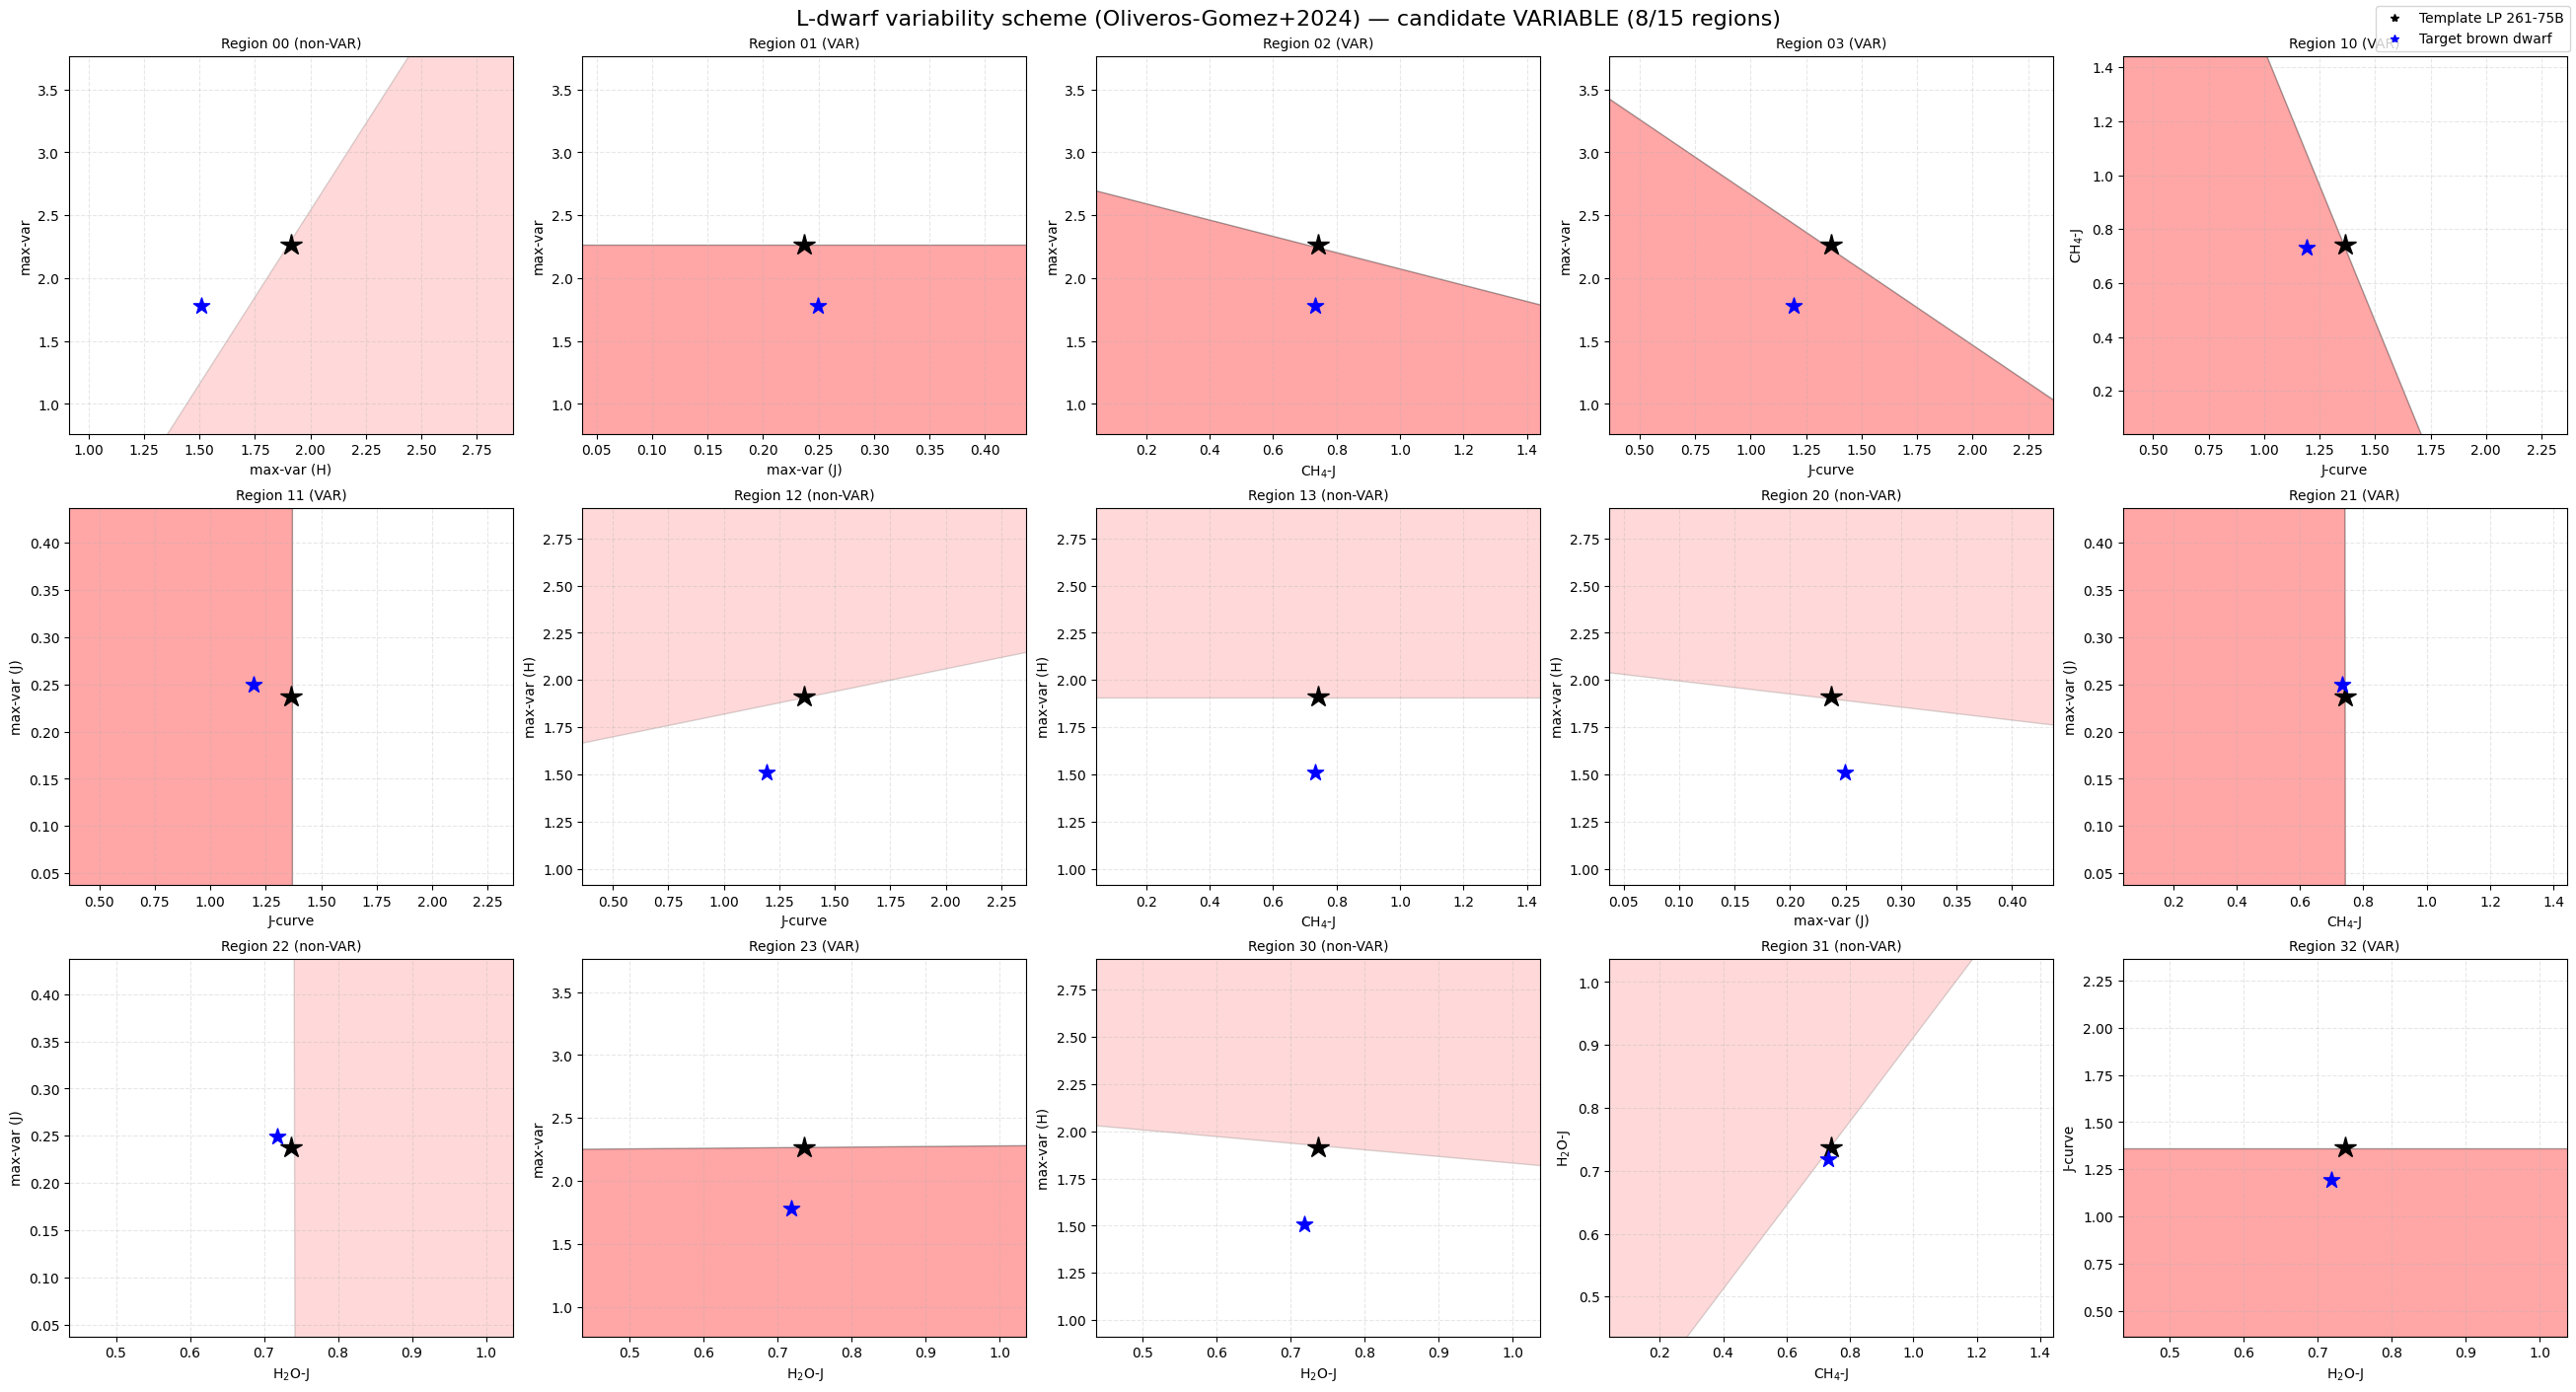

In [9]:
result = classify_variability(
    wave,
    flux,
    spectral_type="L",
    normalize=False,
    plot_index_windows=True,
    plot_diagrams=True,
)

### Example using the T-dwarf scheme
The same workflow applies to T dwarfs by changing the selected spectral type:

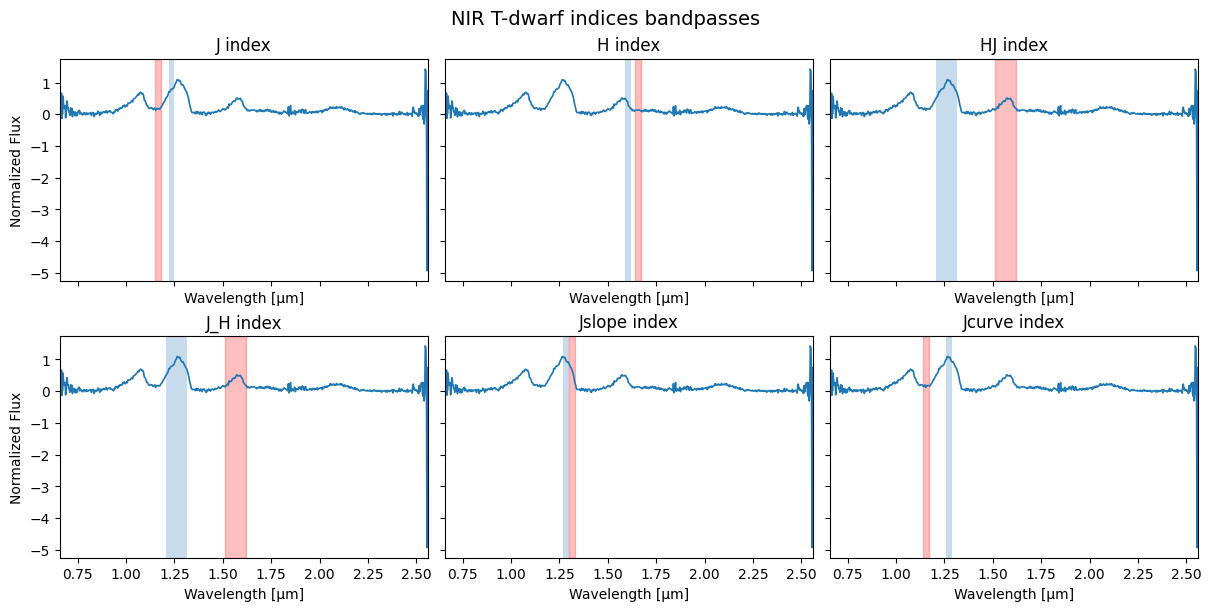

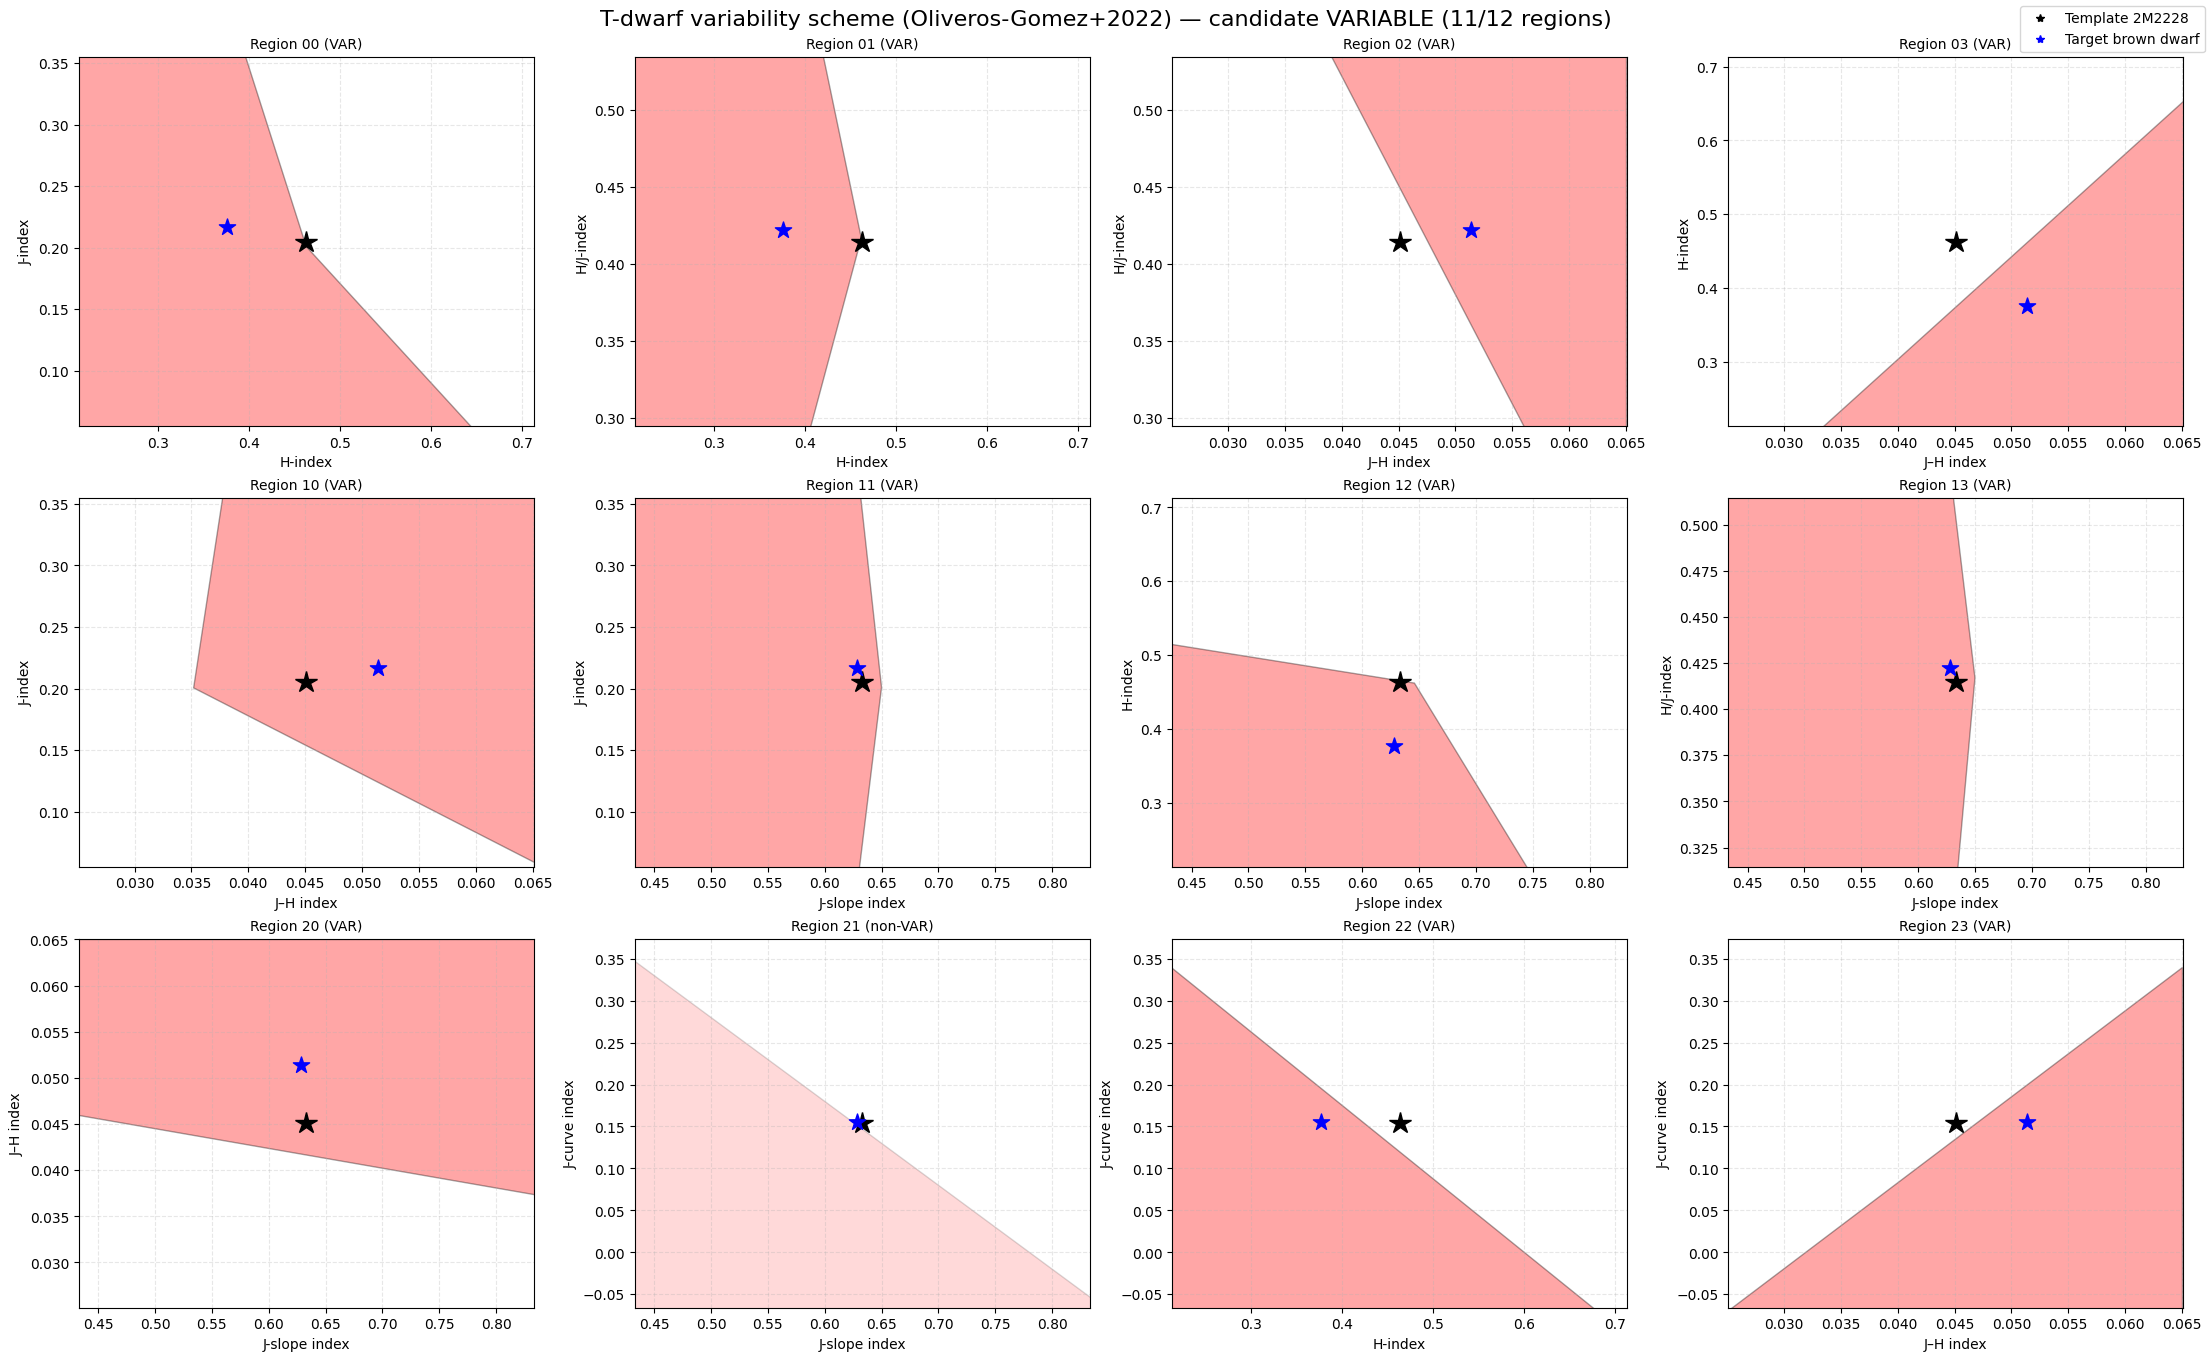

Scheme: Oliveros-Gomez+2022
Spectral type: T
Triggered regions: 11/12 (threshold ≥ 10)
Classification: candidate VARIABLE


In [10]:
# read the T-dwarf spectrum
spec_name = (path_seda / "docs" / "notebooks" / 
             "data" / "2228-nirspec-Tdwarf.txt")
spec = np.loadtxt(spec_name, comments='#').T

wave = spec[0]   # wavelength in microns
flux = spec[1]   # flux

result_T = classify_variability(
    wave,
    flux,
    spectral_type="T",
    normalize=False,
    plot_index_windows=True,
    plot_diagrams=True,
)

print(result_T.summary())

### Notes on normalization

The normalize parameter should be chosen consistently with the input spectrum and the intended use of the indices.

- If the spectrum is already normalized, use normalize=False.

- If the spectrum is not normalized and you want SEDA to apply a median normalization, use normalize=True.

This is especially important for difference-type indices, whose absolute scale depends on the adopted normalization.

### Summary

`seda.classify_variability` provides a single high-level entry point to:

- compute the NIR variability indices,

- classify the target as candidate variable or non-variable,

- inspect the numerical results,

- and generate diagnostic plots.

This makes it straightforward to apply the variability scheme to individual L and T brown dwarf spectra.